# Chapter 01: Quantifying Uncertainty — Python Laboratory
### *Shannon Entropy, The Binary Curve, and The Beta-Binomial Conjugate Engine*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/01_quantifying_uncertainty_entropy_and_bayes.ipynb) | [Prev: Ch 00: The Physics of Belief (Python)](00_the_physics_of_belief.ipynb) | [Next: Ch 02: The Price of Optimism (Python)](02_relative_entropy_and_prior_penalties.ipynb)**

---

## 1. Overview & Setup

In this laboratory, we implement from scratch:
1. **The Binary Entropy Function** $H_2(\theta)$ and verify its physical properties.
2. **The Beta-Binomial Conjugate Updating Engine**: Updating prior beliefs about test flakiness with streaming CI run observations.
3. **Differential Entropy & Effective Width Tracking**: Calculating the exact bits of uncertainty resolved and understanding why continuous entropy turns negative ($W_{\text{eff}} = 2^h$).
4. **The 3-Stage Posterior Sharpening Visualization**: Observing the transition from wide puddle to emerging mound to sharp needle.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist
from scipy.special import betaln, psi

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. Implementation: The Binary Entropy Function $H_2(\theta)$

We write a vectorized function computing $H_2(\theta)$ with safe $0\log_2(0) = 0$ boundary handling.


In [2]:
def binary_entropy(theta):
    # Vectorized binary Shannon entropy in bits
    theta = np.asarray(theta, dtype=np.float64)
    # Clip to avoid log(0) while maintaining continuity
    eps = 1e-15
    theta_safe = np.clip(theta, eps, 1.0 - eps)
    h = -theta_safe * np.log2(theta_safe) - (1.0 - theta_safe) * np.log2(1.0 - theta_safe)
    # Force exact 0 at boundaries
    h = np.where((theta == 0.0) | (theta == 1.0), 0.0, h)
    return h

test_thetas = [0.0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 1.0]
print("=" * 55)
print(f"{'Failure Rate theta':<22} | {'Binary Entropy H2 (Bits)':<25}")
print("=" * 55)
for t in test_thetas:
    print(f"{t:<22.2f} | {binary_entropy(t):<25.4f}")
print("=" * 55)


Failure Rate theta     | Binary Entropy H2 (Bits) 
0.00                   | 0.0000                   
0.01                   | 0.0808                   
0.05                   | 0.2864                   
0.10                   | 0.4690                   
0.25                   | 0.8113                   
0.50                   | 1.0000                   
0.75                   | 0.8113                   
0.90                   | 0.4690                   
0.99                   | 0.0808                   
1.00                   | 0.0000                   


---

## 3. Implementation: Beta Differential Entropy & Effective Width

To measure our ignorance about continuous parameter $\theta \sim \text{Beta}(\alpha, \beta)$, we implement the exact analytical differential entropy in bits:
$$h_{\text{bits}}(\theta) = \frac{1}{\ln 2} \left[ \ln \text{B}(\alpha, \beta) - (\alpha - 1)\psi(\alpha) - (\beta - 1)\psi(\beta) + (\alpha + \beta - 2)\psi(\alpha + \beta) \right]$$

along with the **Effective Width** formula:
$$W_{\text{eff}} = 2^{h_{\text{bits}}}$$


In [3]:
def beta_entropy_bits(alpha, beta):
    # Computes differential entropy of Beta(alpha, beta) in bits
    alpha = float(alpha)
    beta = float(beta)
    ln_b = betaln(alpha, beta)
    term1 = (alpha - 1.0) * psi(alpha)
    term2 = (beta - 1.0) * psi(beta)
    term3 = (alpha + beta - 2.0) * psi(alpha + beta)
    h_nats = ln_b - term1 - term2 + term3
    return h_nats / np.log(2.0)

def effective_width(h_bits):
    return 2.0 ** h_bits

print(f"{'Distribution':<30} | {'Entropy h(theta)':<18} | {'Effective Width W_eff':<22}")
print("-" * 75)
priors_to_test = [
    ("Beta(1, 1) [Flat Uniform Prior]", 1, 1),
    ("Beta(2, 8) [Weakly Informative]", 2, 8),
    ("Beta(10, 90) [100 runs evidence]", 10, 90),
    ("Beta(100, 900) [1000 runs evidence]", 100, 900)
]
for name, a, b in priors_to_test:
    h = beta_entropy_bits(a, b)
    w = effective_width(h)
    print(f"{name:<30} | {h:>8.4f} bits     | {w:>10.4f} of unit interval")


Distribution                   | Entropy h(theta)   | Effective Width W_eff 
---------------------------------------------------------------------------
Beta(1, 1) [Flat Uniform Prior] |   0.0000 bits     |     1.0000 of unit interval
Beta(2, 8) [Weakly Informative] |  -1.1468 bits     |     0.4516 of unit interval
Beta(10, 90) [100 runs evidence] |  -3.0544 bits     |     0.1204 of unit interval
Beta(100, 900) [1000 runs evidence] |  -4.6769 bits     |     0.0391 of unit interval


---

## 4. Simulation: The 3-Stage Posterior Sharpening & Entropy Decay

We simulate a test with true flakiness rate $\theta_{\text{true}} = 0.08$ (fails $8\%$ of the time).
We observe sequential test runs across $N = 250$ executions and visualize:
1. **The 3 Stages of Belief** side-by-side: $N=2$ (Puddle), $N=10$ (Mound), and $N=100$ (Needle).
2. **Entropy Decay & Effective Width Contraction**: Proving the law of diminishing returns.


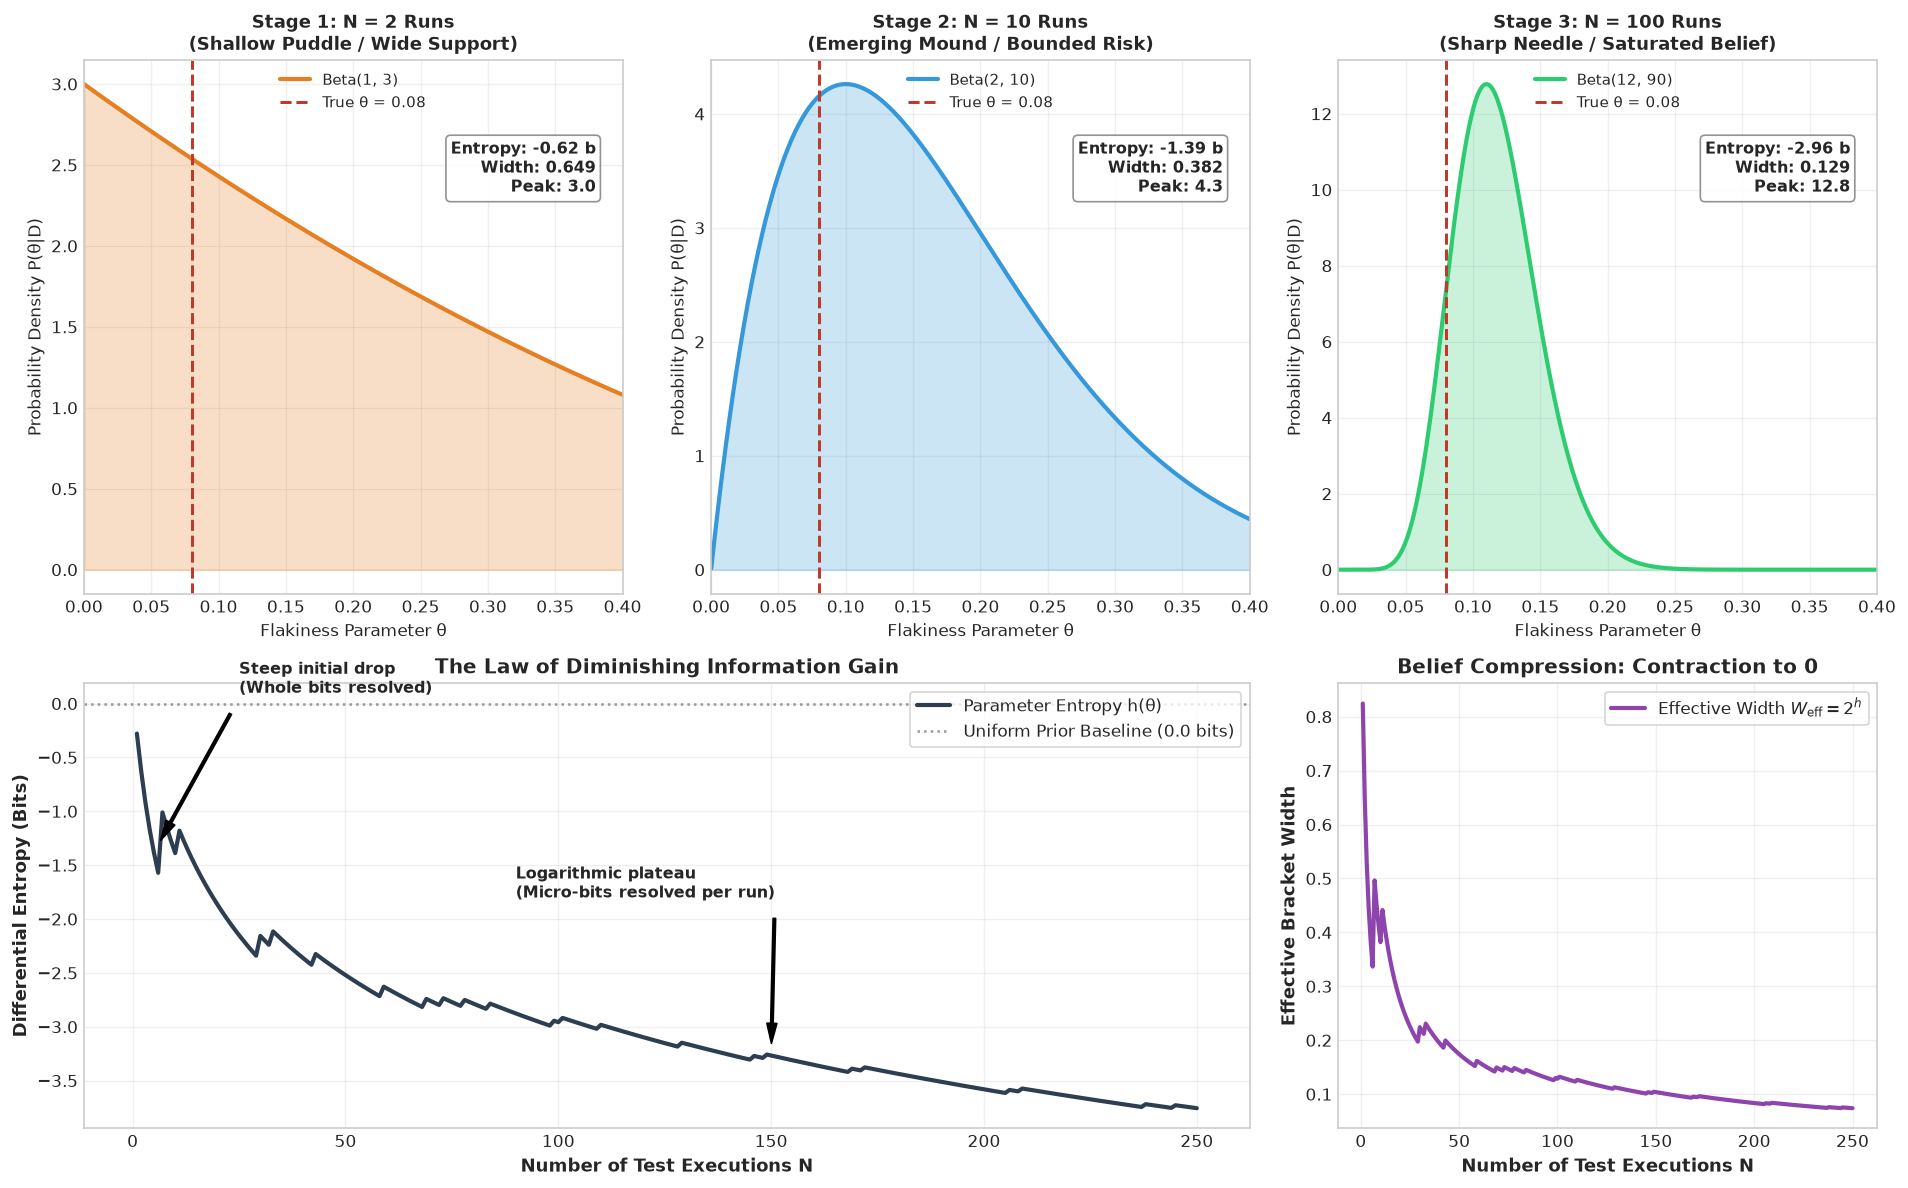

In [4]:
np.random.seed(42)
theta_true = 0.08
num_runs = 250
# Generate synthetic test execution history (1 = Fail, 0 = Pass)
test_runs = (np.random.uniform(0, 1, size=num_runs) < theta_true).astype(int)

# Create 4-panel diagnostic figure
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1.2, 1.0])

theta_grid = np.linspace(0.0001, 0.45, 500)
alpha_0, beta_0 = 1.0, 1.0

# -----------------------------------------------------------
# Top Row: The 3 Stages of Belief (Separate subplots for clarity)
# -----------------------------------------------------------
milestones = [
    (2, "Stage 1: N = 2 Runs\n(Shallow Puddle / Wide Support)", '#e67e22'),
    (10, "Stage 2: N = 10 Runs\n(Emerging Mound / Bounded Risk)", '#3498db'),
    (100, "Stage 3: N = 100 Runs\n(Sharp Needle / Saturated Belief)", '#2ecc71')
]

for idx, (N_cp, title, col) in enumerate(milestones):
    ax = fig.add_subplot(gs[0, idx])
    k_cp = np.sum(test_runs[:N_cp])
    a_cp = alpha_0 + k_cp
    b_cp = beta_0 + (N_cp - k_cp)
    h_cp = beta_entropy_bits(a_cp, b_cp)
    w_cp = effective_width(h_cp)
    
    pdf = beta_dist.pdf(theta_grid, a_cp, b_cp)
    ax.plot(theta_grid, pdf, color=col, lw=2.5, label=f"Beta({int(a_cp)}, {int(b_cp)})")
    ax.fill_between(theta_grid, pdf, color=col, alpha=0.25)
    ax.axvline(theta_true, color='#c0392b', ls='--', lw=1.8, label=f"True θ = {theta_true}")
    
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel("Flakiness Parameter θ", fontsize=10)
    ax.set_ylabel("Probability Density P(θ|D)", fontsize=10)
    ax.set_xlim(0, 0.40)
    
    # Annotate metrics
    ax.text(0.95, 0.85, f"Entropy: {h_cp:+.2f} b\nWidth: {w_cp:.3f}\nPeak: {np.max(pdf):.1f}",
            transform=ax.transAxes, ha='right', va='top', fontsize=9.5, fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.85, ec="gray"))
    ax.legend(loc='upper center', fontsize=9)
    ax.grid(True, alpha=0.3)

# -----------------------------------------------------------
# Bottom Row: Left = Entropy Decay, Right = Effective Width
# -----------------------------------------------------------
n_range = np.arange(1, 251)
cum_failures = np.cumsum(test_runs)
cum_passes = n_range - cum_failures

entropy_curve = [beta_entropy_bits(alpha_0 + k, beta_0 + p) for k, p in zip(cum_failures, cum_passes)]
width_curve = [effective_width(h) for h in entropy_curve]

# Panel 4: Entropy Decay vs N
ax_ent = fig.add_subplot(gs[1, :2])
ax_ent.plot(n_range, entropy_curve, color='#2c3e50', lw=2.5, label='Parameter Entropy h(θ)')
ax_ent.axhline(0, color='gray', ls=':', alpha=0.8, label='Uniform Prior Baseline (0.0 bits)')
ax_ent.set_xlabel("Number of Test Executions N", fontsize=11, fontweight='bold')
ax_ent.set_ylabel("Differential Entropy (Bits)", fontsize=11, fontweight='bold')
ax_ent.set_title("The Law of Diminishing Information Gain", fontsize=12, fontweight='bold')

# Annotations
ax_ent.annotate("Steep initial drop\n(Whole bits resolved)", xy=(5, entropy_curve[4]), xytext=(25, 0.1),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
                fontsize=9.5, fontweight='bold')
ax_ent.annotate("Logarithmic plateau\n(Micro-bits resolved per run)", xy=(150, entropy_curve[149]), xytext=(90, -1.8),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
                fontsize=9.5, fontweight='bold')
ax_ent.legend(loc='upper right', frameon=True)
ax_ent.grid(True, alpha=0.3)

# Panel 5: Effective Support Width Contraction
ax_w = fig.add_subplot(gs[1, 2])
ax_w.plot(n_range, width_curve, color='#8e44ad', lw=2.5, label=r'Effective Width $W_{\mathrm{eff}} = 2^h$')
ax_w.set_xlabel("Number of Test Executions N", fontsize=11, fontweight='bold')
ax_w.set_ylabel("Effective Bracket Width", fontsize=11, fontweight='bold')
ax_w.set_title("Belief Compression: Contraction to 0", fontsize=12, fontweight='bold')
ax_w.grid(True, alpha=0.3)
ax_w.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


---

## 5. 3-Tier Exercises & Explorations

### Tier 1: Warmup — Entropy Calculation & Effective Width
1. Compute the binary entropy $H_2(\theta)$ for a test with $\theta = 0.05$ (fails $5\%$ of the time).
2. For a test posterior $\text{Beta}(4, 36)$, calculate the differential entropy $h(\theta)$ in bits and its corresponding effective width $W_{\text{eff}} = 2^h$.
3. What is the expected failure rate for a test with prior $\text{Beta}(2, 98)$ after observing $1$ failure in $10$ runs?

### Tier 2: Intermediate — Prior Sensitivity Analysis
Compare two engineering teams analyzing the exact same test outcome: **$1$ failure in $20$ runs**.
* **Team A (Skeptical)**: Uses prior $\text{Beta}(1, 99)$ (assumes tests are generally solid).
* **Team B (Agnostic)**: Uses prior $\text{Beta}(1, 1)$ (assumes nothing).
Calculate the posterior mean, 95% credible interval, and posterior entropy for both teams.

### Tier 3: Advanced Research — The Information Stopping Rule
Write an automated function `run_test_until_certain(theta_true, target_entropy_reduction=2.0)` that executes simulated CI runs one-by-one.
* It stops running tests as soon as the total parameter entropy has dropped by $2.0\text{ bits}$ from the prior.
* Plot the distribution of required test runs $N_{\text{stop}}$ across 1,000 Monte Carlo trials.


In [5]:
# Solution verification for Tier 1:
h_05 = binary_entropy(0.05)
h_post_t1 = beta_entropy_bits(4, 36)
w_post_t1 = effective_width(h_post_t1)
mean_t1 = (2 + 1) / (2 + 98 + 10)

print("--- Tier 1 Solutions ---")
print(f"1. Binary entropy H2(0.05):              {h_05:.4f} bits")
print(f"2. Beta(4, 36) Differential Entropy:     {h_post_t1:.4f} bits")
print(f"   Beta(4, 36) Effective Width:          {w_post_t1:.4f} ({w_post_t1*100:.2f}% of interval)")
print(f"3. Posterior Mean for Beta(2, 98) + (1, 9): {mean_t1:.4f} ({mean_t1*100:.2f}%)")


--- Tier 1 Solutions ---
1. Binary entropy H2(0.05):              0.2864 bits
2. Beta(4, 36) Differential Entropy:     -2.4620 bits
   Beta(4, 36) Effective Width:          0.1815 (18.15% of interval)
3. Posterior Mean for Beta(2, 98) + (1, 9): 0.0273 (2.73%)


In [6]:
# Solution verification for Tier 2:
# Outcome: k=1, N=20
k_obs, N_obs = 1, 20

# Team A: Beta(1, 99) -> Beta(1 + 1, 99 + 19) = Beta(2, 118)
a_A, b_A = 1 + k_obs, 99 + (N_obs - k_obs)
mean_A = a_A / (a_A + b_A)
ci_A = beta_dist.interval(0.95, a_A, b_A)
h_A = beta_entropy_bits(a_A, b_A)

# Team B: Beta(1, 1) -> Beta(1 + 1, 1 + 19) = Beta(2, 20)
a_B, b_B = 1 + k_obs, 1 + (N_obs - k_obs)
mean_B = a_B / (a_B + b_B)
ci_B = beta_dist.interval(0.95, a_B, b_B)
h_B = beta_entropy_bits(a_B, b_B)

print("\n--- Tier 2 Solutions ---")
print(f"Team A (Skeptical Prior Beta(1, 99)):")
print(f"  Posterior Mean: {mean_A:.4f} ({mean_A*100:.2f}%)")
print(f"  95% CI:         [{ci_A[0]:.4f}, {ci_A[1]:.4f}]")
print(f"  Entropy:        {h_A:.4f} bits")

print(f"\nTeam B (Agnostic Prior Beta(1, 1)):")
print(f"  Posterior Mean: {mean_B:.4f} ({mean_B*100:.2f}%)")
print(f"  95% CI:         [{ci_B[0]:.4f}, {ci_B[1]:.4f}]")
print(f"  Entropy:        {h_B:.4f} bits")



--- Tier 2 Solutions ---
Team A (Skeptical Prior Beta(1, 99)):
  Posterior Mean: 0.0167 (1.67%)
  95% CI:         [0.0020, 0.0459]
  Entropy:        -4.6376 bits

Team B (Agnostic Prior Beta(1, 1)):
  Posterior Mean: 0.0909 (9.09%)
  95% CI:         [0.0117, 0.2382]
  Entropy:        -2.2219 bits


In [7]:
# Solution verification for Tier 3:
print("\n--- Tier 3 Simulation: Information Stopping Rule ---")

def run_test_until_certain(theta_true=0.08, target_drop=2.0, max_runs=100):
    a, b = 1.0, 1.0
    h_init = beta_entropy_bits(a, b) # 0.0 bits
    for n in range(1, max_runs + 1):
        y = 1 if np.random.rand() < theta_true else 0
        a += y
        b += (1 - y)
        h_current = beta_entropy_bits(a, b)
        if (h_init - h_current) >= target_drop:
            return n
    return max_runs

trials = 1000
stopping_runs = [run_test_until_certain(theta_true=0.08, target_drop=2.0) for _ in range(trials)]
avg_runs = np.mean(stopping_runs)
median_runs = np.median(stopping_runs)

print(f"Monte Carlo Trials: {trials:,}")
print(f"Target Entropy Drop: 2.0 bits (compressing belief by 4x)")
print(f"Average Runs to Stop: {avg_runs:.1f} runs")
print(f"Median Runs to Stop:  {median_runs:.1f} runs")
print(f"90th Percentile:      {np.percentile(stopping_runs, 90):.1f} runs")



--- Tier 3 Simulation: Information Stopping Rule ---


Monte Carlo Trials: 1,000
Target Entropy Drop: 2.0 bits (compressing belief by 4x)
Average Runs to Stop: 17.6 runs
Median Runs to Stop:  17.0 runs
90th Percentile:      31.0 runs
